In [2]:
import pandas as pd
import numpy as np


In [3]:
df=pd.read_csv("../data/Dataset.csv")
display(df.head())

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


Step 1: Select relevant dataset features.

In [4]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='str')

In [25]:
X=df[['release_year','rating','country','listed_in','director','date_added']]
y=df['type']
print(X['country'].head())

0    United States
1           France
2    United States
3           Brazil
4    United States
Name: country, dtype: str


In [7]:
print(X.shape)
print(X.isnull().sum())

(8790, 6)
release_year    0
rating          0
country         0
listed_in       0
director        0
date_added      0
dtype: int64


Step 2: Encode categorical variables.

In [ ]:
X=X.copy()
X['date_added']=pd.to_datetime(X['date_added'].astype(str).str.strip(),errors='coerce')
X['year_added']=X['date_added'].dt.year
X['montd_added']=X['date_added'].dt.month
X=X.drop(columns='date_added')


In [29]:
X['has_director']=(X['director']!='Unknown').astype(int)
X=X.drop(columns='director')

In [26]:
X['country']=X['country'].str.split(',').str[0].str.strip()
top_countries=X['country'].value_counts().head(10).index
X['country']=X['country'].where(X['country'].isin(top_countries),'Other')

In [27]:
print(X['country'].value_counts())

country
United States     3240
Other             2008
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


In [31]:
genres = X['listed_in'].str.get_dummies(sep=', ')
X = X.drop(columns='listed_in')

In [32]:
X = pd.get_dummies(X, columns=['rating', 'country'], drop_first=True)
X = pd.concat([X, genres], axis=1)

In [33]:
y = (df['type'] == 'TV Show').astype(int)  

In [34]:
print(X.shape)
print(X.dtypes.unique())
print(X.isnull().sum().sum())

(8790, 69)
[dtype('int64') dtype('int32') dtype('bool')]
0


Step 3: Train classification models.

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)

(7032, 69) (1758, 69)


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained
Gradient Boosting trained


Step 4: Evaluate prediction performance.

In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
print(results_df.round(3).to_string(index=False))

              Model  Accuracy  Precision  Recall    F1
Logistic Regression     1.000        1.0   1.000 1.000
      Random Forest     1.000        1.0   1.000 1.000
      Decision Tree     0.999        1.0   0.996 0.998
  Gradient Boosting     0.998        1.0   0.992 0.996


In [39]:
from sklearn.metrics import classification_report, confusion_matrix

best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
pred = best_model.predict(X_test)

print(best_name)
print(classification_report(y_test, pred, target_names=["Movie", "TV Show"]))
print(confusion_matrix(y_test, pred))

Logistic Regression
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     TV Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758

[[1225    0]
 [   0  533]]


Step 5: Compare model accuracy.

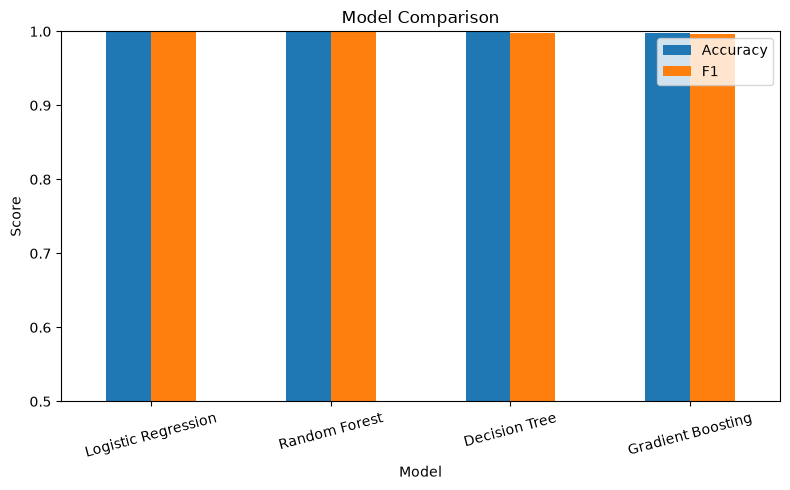

In [40]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[["Accuracy", "F1"]].plot.bar(figsize=(8, 5), rot=15)
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0.5, 1.0)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

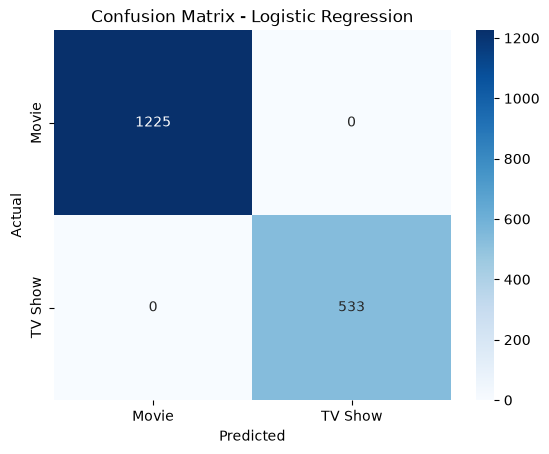

In [41]:
import seaborn as sns

cm = confusion_matrix(y_test, best_model.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Movie", "TV Show"], yticklabels=["Movie", "TV Show"])
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()